# NOTEBOOK RFM
## Mục tiêu
Ghi nội dung thực hiện tại đây.

In [6]:
from pathlib import Path
from pyspark.sql import SparkSession, functions as F
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
while not (ROOT / "src" / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROCESSED, FIG = ROOT / "data" / "processed", ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

spark = (SparkSession.builder.master("local[*]")
         .config("spark.driver.memory", "8g").getOrCreate())
tx = spark.read.parquet(str(PROCESSED / "transactions.parquet"))
cu = spark.read.parquet(str(PROCESSED / "customer.parquet"))
ar = spark.read.parquet(str(PROCESSED / "article.parquet"))
t = tx.withColumn("t_dat", F.to_date("t_dat"))
print("ROOT:", ROOT)

ROOT: c:\Users\tranq\bao-cao-phan-khuc-khach-hang-rfm


Giao dich theo thang

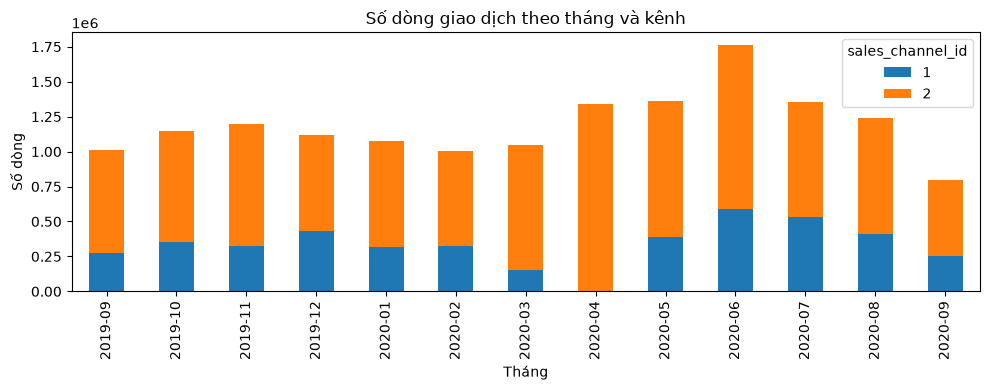

In [7]:
thang = (t.groupBy(F.date_format("t_dat", "yyyy-MM").alias("thang"), "sales_channel_id")
           .count().toPandas())
p = thang.pivot(index="thang", columns="sales_channel_id", values="count").fillna(0)
p.plot(kind="bar", stacked=True, figsize=(10, 4), title="Số dòng giao dịch theo tháng và kênh")
plt.xlabel("Tháng"); plt.ylabel("Số dòng")
plt.tight_layout(); plt.savefig(FIG / "01_thang_kenh.png"); plt.show()

Phan bo tuoi

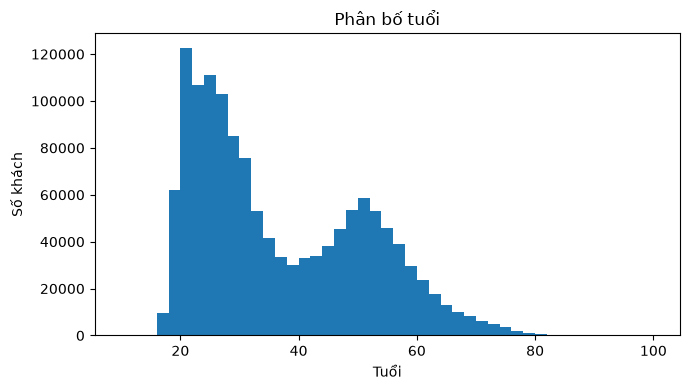

In [8]:
age = cu.select("age").dropna().toPandas()["age"]
plt.figure(figsize=(7, 4))
plt.hist(age, bins=range(10, 101, 2))
plt.title("Phân bố tuổi"); plt.xlabel("Tuổi"); plt.ylabel("Số khách")
plt.tight_layout(); plt.savefig(FIG / "02_tuoi.png"); plt.show()

Nhom san pham

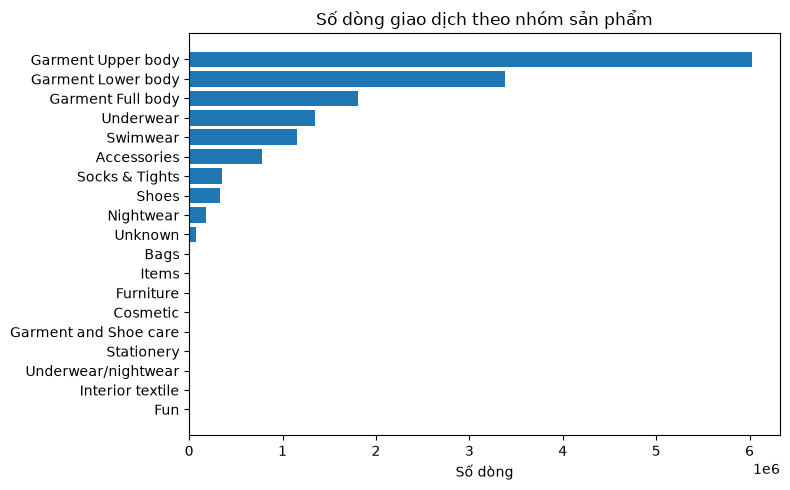

In [9]:
nhom = (tx.join(ar.select("article_id", "product_group_name"), "article_id")
          .groupBy("product_group_name").count().toPandas().sort_values("count"))
plt.figure(figsize=(8, 5))
plt.barh(nhom["product_group_name"], nhom["count"])
plt.title("Số dòng giao dịch theo nhóm sản phẩm"); plt.xlabel("Số dòng")
plt.tight_layout(); plt.savefig(FIG / "03_nhom_san_pham.png"); plt.show()

F và M mỗi khách, trước và sau log1p

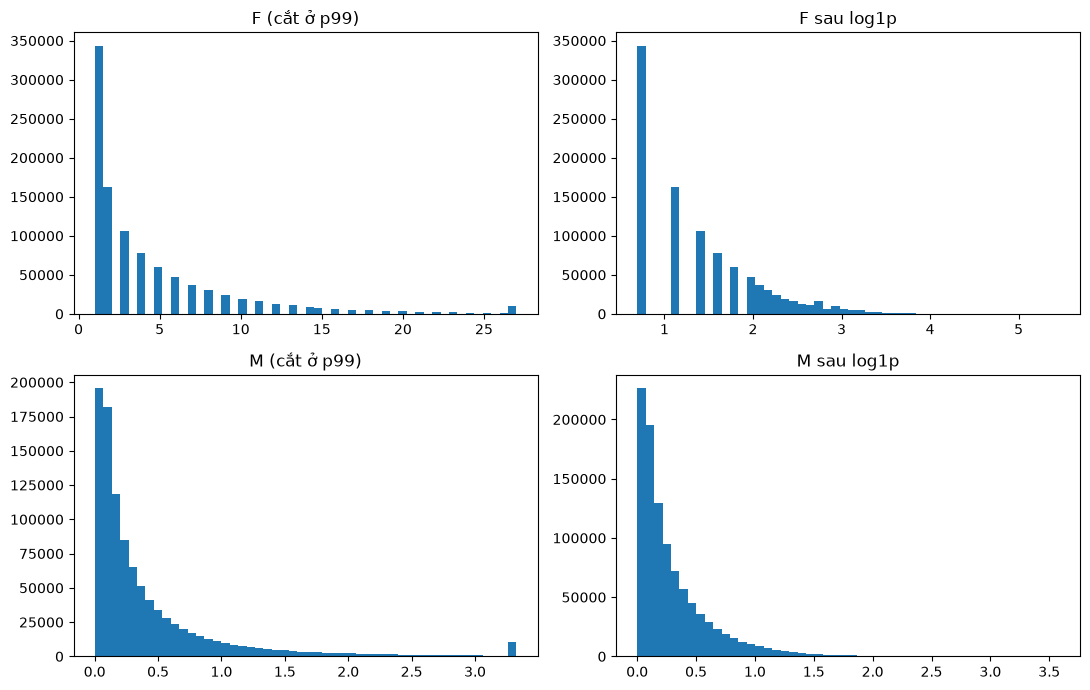

Skewness F: 4.44 -> sau log1p: 0.82
Skewness M: 6.17 -> sau log1p: 2.07


In [10]:
kh = (t.groupBy("customer_id")
        .agg(F.countDistinct("t_dat").alias("F"), F.sum("price").alias("M")).toPandas())

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
ax[0, 0].hist(kh["F"].clip(upper=kh["F"].quantile(0.99)), bins=50); ax[0, 0].set_title("F (cắt ở p99)")
ax[0, 1].hist(np.log1p(kh["F"]), bins=50);                          ax[0, 1].set_title("F sau log1p")
ax[1, 0].hist(kh["M"].clip(upper=kh["M"].quantile(0.99)), bins=50); ax[1, 0].set_title("M (cắt ở p99)")
ax[1, 1].hist(np.log1p(kh["M"]), bins=50);                          ax[1, 1].set_title("M sau log1p")
plt.tight_layout(); plt.savefig(FIG / "04_F_M_log.png"); plt.show()

print("Skewness F:", round(kh["F"].skew(), 2), "-> sau log1p:", round(np.log1p(kh["F"]).skew(), 2))
print("Skewness M:", round(kh["M"].skew(), 2), "-> sau log1p:", round(np.log1p(kh["M"]).skew(), 2))

In [11]:
for k in [1, 10, 100, 1000]:
    print(f"M x {k:>4}: skewness sau log1p =", round(np.log1p(kh["M"] * k).skew(), 2))

M x    1: skewness sau log1p = 2.07
M x   10: skewness sau log1p = 0.81
M x  100: skewness sau log1p = 0.21
M x 1000: skewness sau log1p = 0.05
